In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/workstation-rental-price-tier-prediction/kaggle_ready_dataset/sample_submission.csv
/kaggle/input/competitions/workstation-rental-price-tier-prediction/kaggle_ready_dataset/train.csv
/kaggle/input/competitions/workstation-rental-price-tier-prediction/kaggle_ready_dataset/test.csv


## Q1 FACTS
shape train/test: (279746, 60) (114538, 59)
dtype counts: {'float64': 26, 'int64': 17, 'object': 17}
rows in duplicate groups: 1912 | contradicting rows dropped: 119 | rows 279746 -> 278543
missing % (top 8): {'borough': 76.7, 'score_condition': 19.4, 'score_accuracy': 19.4, 'score_support': 19.4, 'first_review_date': 19.4, 'last_review_date': 19.4, 'score_onboarding': 19.4, 'score_value': 19.4}
class balance: {1: 0.239, 2: 0.291, 3: 0.217, 4: 0.252}
metro units != whole+private+shared: 3428 | metro units > portfolio: 1849
distinct values: {'operator_ref': 41903, 'zone': 1380, 'space_class': 131, 'metro': 16, 'borough': 55, 'facilities': 251649}
lat range: -4.8 111.8 | lon range: -123.7 87.0


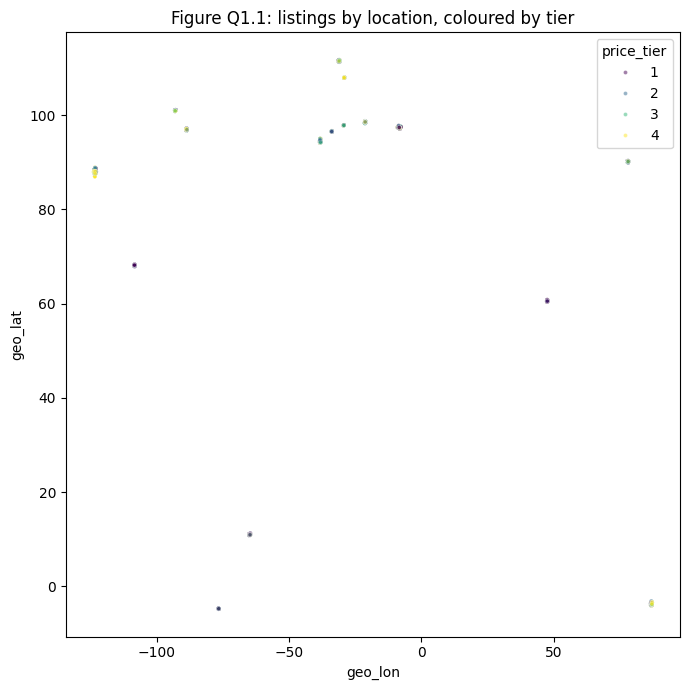

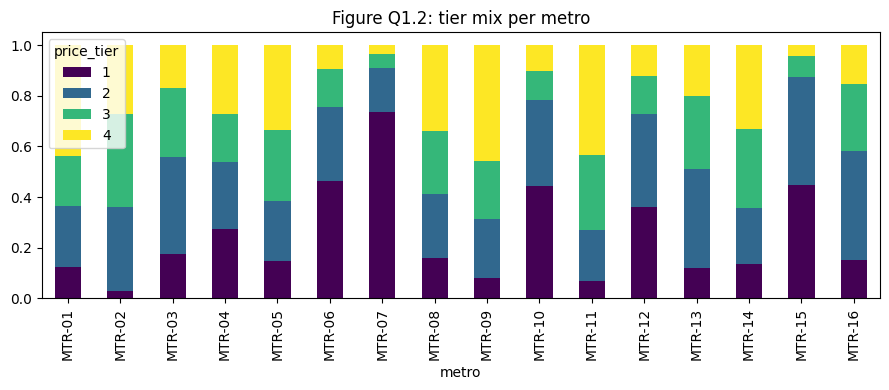

[   49s] Q0 baseline raw: {'macro_f1': 0.6643, 'n_features': 52}
[   92s] Q2 combined: {'macro_f1': 0.659, 'n_features': 65}


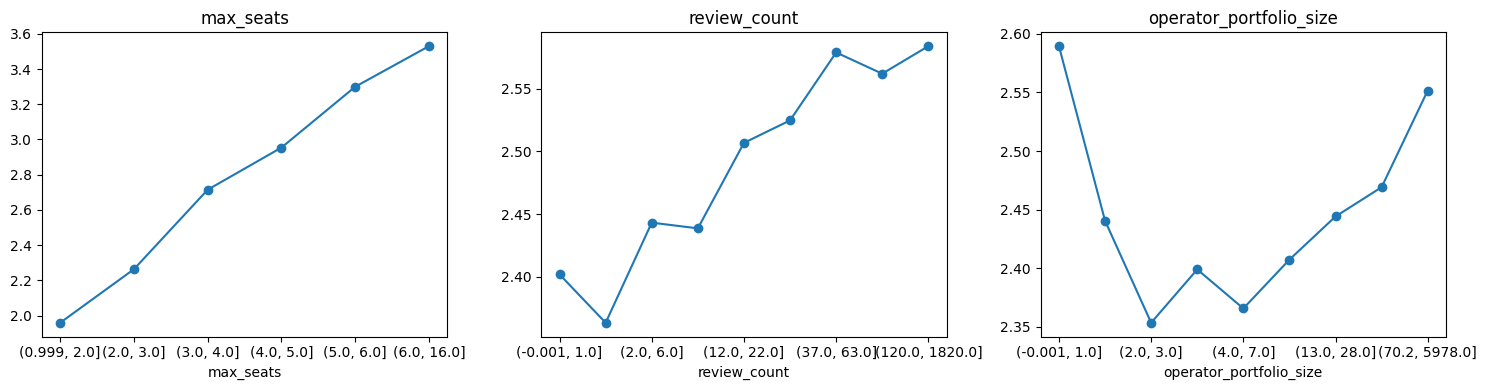


## Q3 FACTS
skewed columns logged: ['operator_portfolio_size', 'max_seats', 'utility_rooms', 'zones', 'workstations', 'min_term_days', 'max_term_days', 'min_term_floor', 'min_term_ceiling', 'max_term_floor', 'max_term_ceiling', 'min_term_avg', 'max_term_avg', 'review_count', 'review_count_12m', 'review_count_30d', 'review_count_prev_yr', 'score_overall', 'score_accuracy', 'score_condition', 'score_onboarding', 'score_support', 'score_access', 'score_value', 'operator_metro_units', 'operator_metro_whole', 'operator_metro_private', 'operator_metro_shared', 'reviews_per_month', 'share_whole', 'share_private', 'share_shared', 'metro_share', 'score_mean', 'has_reviews', 'seats_per_ws', 'metro_sum_mismatch', 'metro_over_portfolio']
[  149s] Q3 log+bins (LightGBM): {'macro_f1': 0.6609, 'n_features': 104}
[  160s] Q3 linear before: {'macro_f1': 0.5279, 'n_features': 54}
[  214s] Q3 linear after: {'macro_f1': 0.5339, 'n_features': 93}


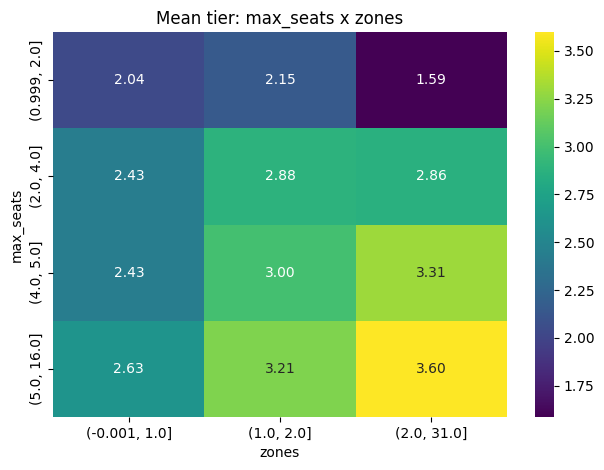


## Q4 FACTS
mean-tier grid (rows=max_seats bins, cols=zones bins):
zones         (-0.001, 1.0]  (1.0, 2.0]  (2.0, 31.0]
max_seats                                           
(0.999, 2.0]           2.04        2.15         1.59
(2.0, 4.0]             2.43        2.88         2.86
(4.0, 5.0]             2.43        3.00         3.31
(5.0, 16.0]            2.63        3.21         3.60
[  257s] Q4 interactions: {'macro_f1': 0.6615, 'n_features': 69}

## Q5 FACTS
date columns unparsed %: {'snapshot_start_date': 0.0, 'snapshot_end_date': 0.0, 'first_review_date': 19.0, 'last_review_date': 19.0}
distinct facility codes: 144 | flags kept (>3% of listings): 96 | facilities per listing: mean 30.1 min 0 max 101


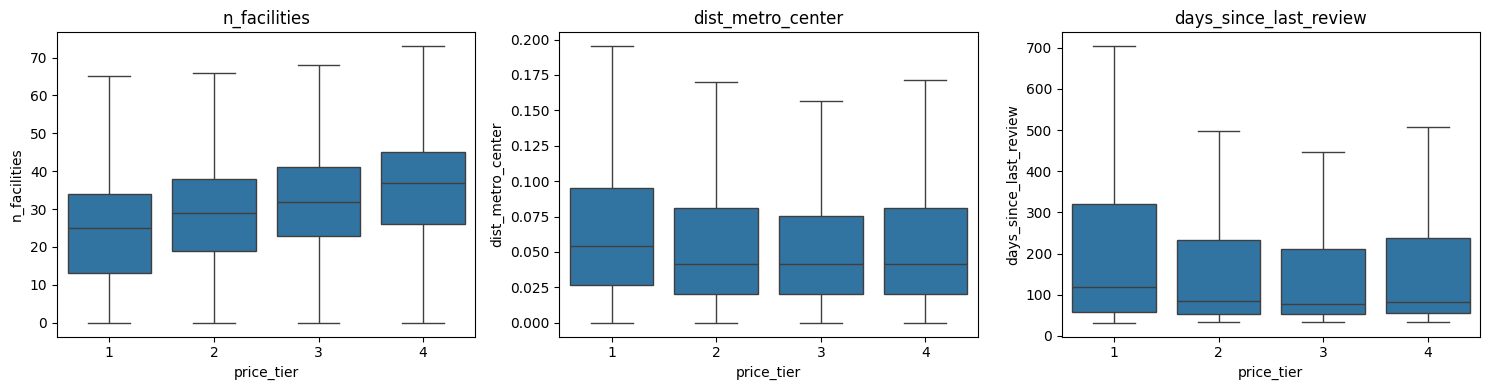

mean by tier:
            n_facilities  dist_metro_center  days_since_last_review
price_tier                                                         
1                  24.75               0.08                  314.76
2                  28.59               0.07                  250.53
3                  31.45               0.07                  242.24
4                  35.63               0.07                  253.62
[  343s] Q5 extracted: {'macro_f1': 0.6896, 'n_features': 168}
[  404s] Q6a group counts/means (no target): {'macro_f1': 0.69, 'n_features': 172}
[  472s] Q6b + target encoding inside CV: {'macro_f1': 0.6873, 'n_features': 174}

## Q6 FACTS
operator_listings: median 49.0 max 1773.0 | groups: operators 55355 zones 1396


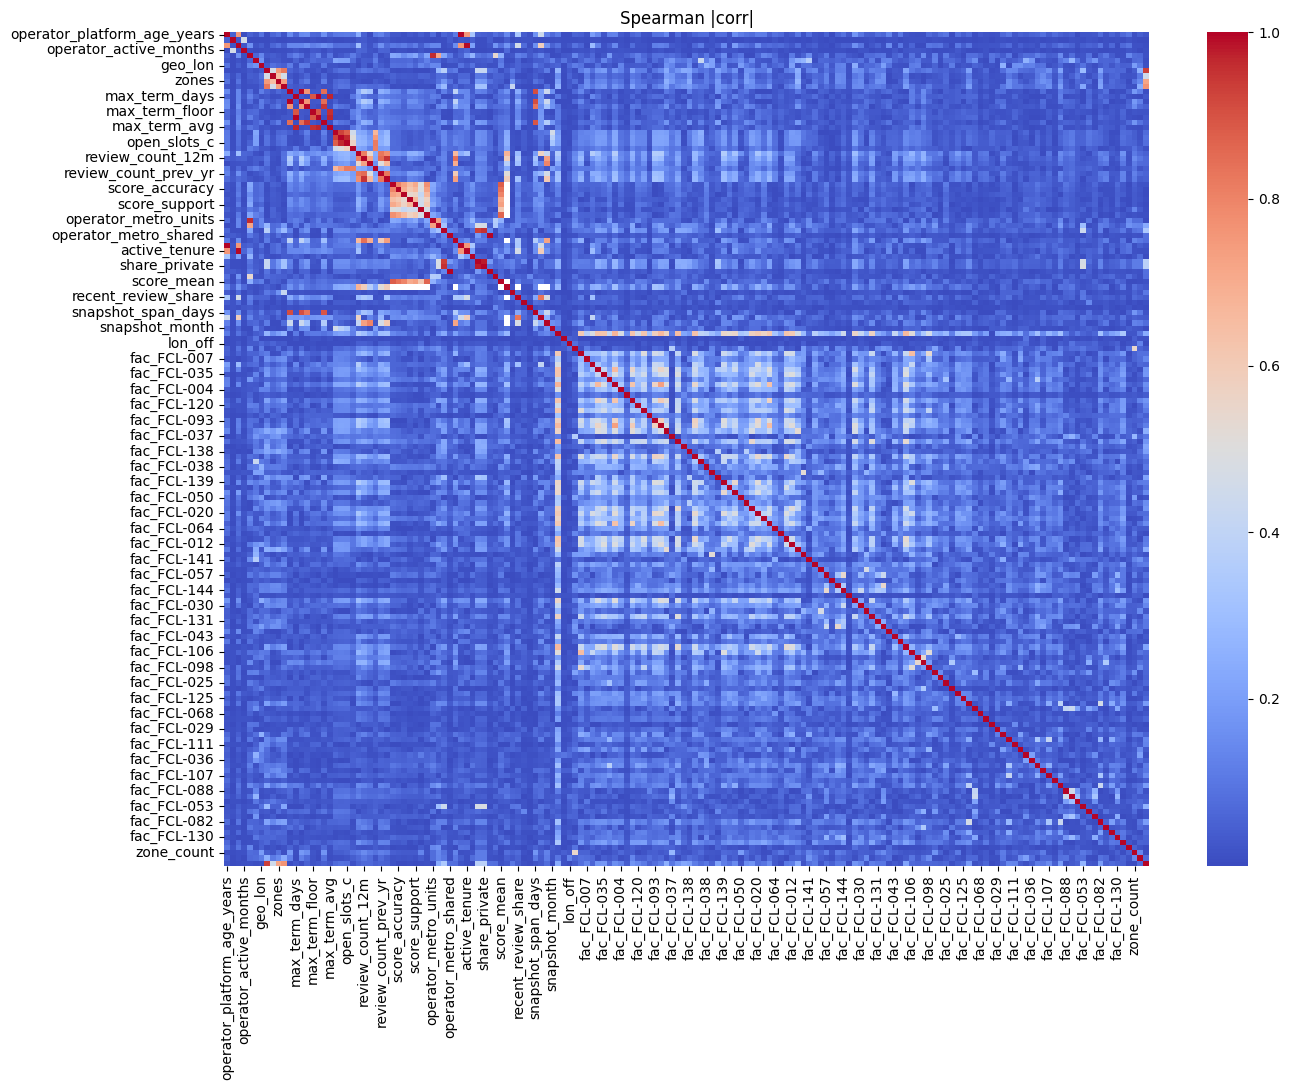


## Q7 FACTS
correlated pairs (|rho|>0.9):
min_term_days                min_term_floor          1.000
max_term_days                max_term_ceiling        1.000
operator_metro_shared        share_shared            1.000
operator_platform_age_years  platform_tenure         0.997
operator_active_years        active_tenure           0.996
share_whole                  share_private           0.978
max_term_days                max_term_avg            0.971
max_term_ceiling             max_term_avg            0.971
open_slots_b                 open_slots_c            0.968
operator_portfolio_size      operator_metro_units    0.961
max_term_floor               max_term_avg            0.955
operator_metro_private       share_private           0.953
review_count_12m             booked_load             0.950
min_term_ceiling             min_term_avg            0.948
operator_metro_private       share_whole             0.934
dropped columns: ['min_term_floor', 'max_term_ceiling', 'min_term_avg', 

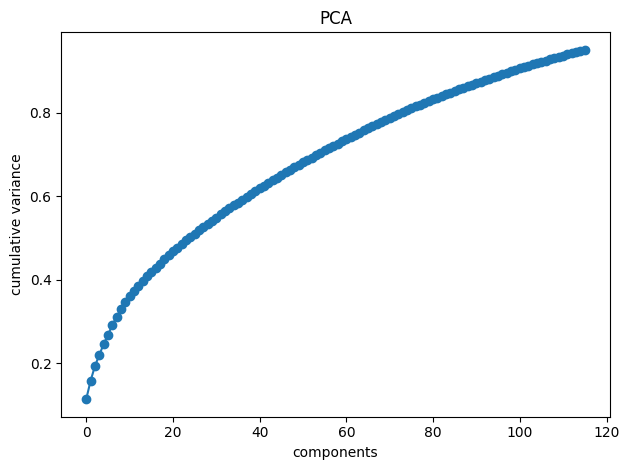


## Q9 FACTS
components for 95% variance: 116 of 147 numeric columns
[  903s] Q9 numeric only, no PCA: {'macro_f1': 0.6824, 'n_features': 147}
[  964s] Q9 numeric only, PCA: {'macro_f1': 0.5679, 'n_features': 116}


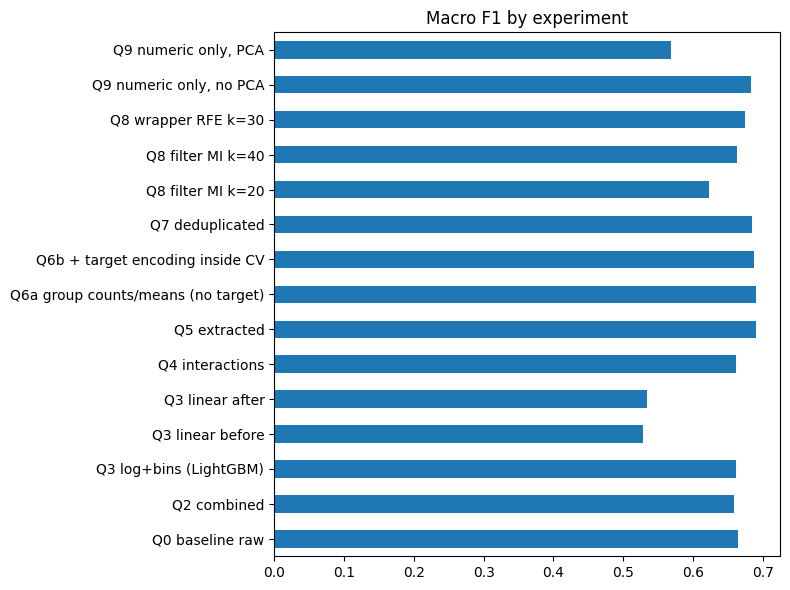


## Q10 FACTS
features: baseline 52 -> Q2 adds 13 | Q5 adds 104 (drops facilities) | Q6 adds 4 | Q7 drops 15 -> final 157
top 15 features by gain (share %):
geo_lat                   10.06
zones                      7.78
max_seats                  7.31
geo_lon                    5.94
min_term_days              4.84
access_type                2.87
dist_metro_center          2.74
metro                      2.69
min_term_ceiling           2.66
utility_rooms              2.17
fac_FCL-069                2.11
score_access               1.92
zone_mean_seats            1.88
compliance_status          1.84
days_since_last_review     1.61

======================== COPY EVERYTHING BELOW THIS LINE ========================
## Q1 FACTS
shape train/test: (279746, 60) (114538, 59)
dtype counts: {'float64': 26, 'int64': 17, 'object': 17}
rows in duplicate groups: 1912 | contradicting rows dropped: 119 | rows 279746 -> 278543
missing % (top 8): {'borough': 76.7, 'score_condition': 19.4, 'score_accuracy'

In [2]:
# ===================== MILESTONE 3: ONE CELL =====================
import json, os, time, warnings, collections
import numpy as np, pandas as pd, lightgbm as lgb, matplotlib.pyplot as plt, seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder, TargetEncoder, StandardScaler, MultiLabelBinarizer
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.feature_selection import SelectKBest, mutual_info_classif, RFE
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
warnings.filterwarnings("ignore")

N_ROWS = 60000            # lower to 40000 if you want it faster
OUT = "/kaggle/working"; os.makedirs(f"{OUT}/figs", exist_ok=True)
LOG = f"{OUT}/results.json"
results = json.load(open(LOG)) if os.path.exists(LOG) else {}
notes, T0 = [], time.time()

def say(*a):
    s = " ".join(str(x) for x in a); notes.append(s); print(s, flush=True)
def fig(name):
    plt.tight_layout(); plt.savefig(f"{OUT}/figs/{name}.png", dpi=130); plt.show()
def log(name, score, nfeat):
    results[name] = {"macro_f1": round(float(score), 4), "n_features": int(nfeat)}
    json.dump(results, open(LOG, "w"), indent=2)
    print(f"[{time.time()-T0:5.0f}s] {name}: {results[name]}", flush=True)

# ---------------- load + clean ----------------
D = "/kaggle/input/competitions/workstation-rental-price-tier-prediction/kaggle_ready_dataset/"
train, test = pd.read_csv(D + "train.csv"), pd.read_csv(D + "test.csv")
feat_cols = [c for c in train.columns if c not in ("space_id", "price_tier")]
dup_mask = train.duplicated(subset=feat_cols, keep=False)
dd = train[dup_mask]
bad_idx = dd.index[dd.groupby(feat_cols, dropna=False)["price_tier"].transform("nunique") > 1]
train_clean = train.drop(index=bad_idx).drop_duplicates(subset=feat_cols).reset_index(drop=True)

R = train_clean.drop(columns="price_tier")
yc = train_clean["price_tier"] - 1
groups = train_clean["operator_ref"].fillna("missing")
allx = pd.concat([R, test], ignore_index=True)       # context only, never labels
RAW_DROP = ["space_id", "operator_ref", "bookable", "snapshot_start_date",
            "snapshot_end_date", "first_review_date", "last_review_date"]
X_base = R.drop(columns=RAW_DROP)

# ---------------- Q1 facts ----------------
say("## Q1 FACTS")
say("shape train/test:", train.shape, test.shape)
say("dtype counts:", {str(k): int(v) for k, v in train.dtypes.value_counts().items()})
say("rows in duplicate groups:", int(dup_mask.sum()), "| contradicting rows dropped:", len(bad_idx),
    "| rows", len(train), "->", len(train_clean))
miss = train.isna().mean().mul(100).round(1)
say("missing % (top 8):", miss[miss > 0].sort_values(ascending=False).head(8).to_dict())
say("class balance:", train.price_tier.value_counts(normalize=True).sort_index().round(3).to_dict())
say("metro units != whole+private+shared:",
    int((train.operator_metro_units != train.operator_metro_whole + train.operator_metro_private
         + train.operator_metro_shared).sum()),
    "| metro units > portfolio:", int((train.operator_metro_units > train.operator_portfolio_size).sum()))
say("distinct values:", {c: int(train[c].nunique()) for c in
    ["operator_ref", "zone", "space_class", "metro", "borough", "facilities"]})
say("lat range:", round(float(train.geo_lat.min()), 1), round(float(train.geo_lat.max()), 1),
    "| lon range:", round(float(train.geo_lon.min()), 1), round(float(train.geo_lon.max()), 1))
s0 = train.sample(20000, random_state=42)
plt.figure(figsize=(7, 7))
sns.scatterplot(data=s0, x="geo_lon", y="geo_lat", hue="price_tier", palette="viridis", s=8, alpha=.5)
plt.title("Figure Q1.1: listings by location, coloured by tier"); fig("Q1_1_map")
pd.crosstab(s0.metro, s0.price_tier, normalize="index").plot(kind="bar", stacked=True, figsize=(9, 4), colormap="viridis")
plt.title("Figure Q1.2: tier mix per metro"); fig("Q1_2_metro")

# ---------------- model + scoring helpers ----------------
def make_pipe(X, te_cols=(), selector=None, n_est=300):
    cats = list(X.select_dtypes(exclude="number").columns)
    te = [c for c in te_cols if c in cats]; oc = [c for c in cats if c not in te]
    pre = ColumnTransformer([
        ("te", TargetEncoder(target_type="multiclass", random_state=42), te),
        ("oc", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1,
                              encoded_missing_value=-1), oc)], remainder="passthrough")
    clf = lgb.LGBMClassifier(n_estimators=n_est, learning_rate=0.08, num_leaves=67,
            min_child_samples=170, subsample=0.85, subsample_freq=1, colsample_bytree=0.72,
            reg_lambda=1.5, class_weight="balanced", random_state=42, n_jobs=4, verbose=-1)
    steps = [("pre", pre)]
    if selector is not None: steps += [("imp", SimpleImputer(strategy="median")), ("sel", selector)]
    return Pipeline(steps + [("clf", clf)])

IDX = R.sample(N_ROWS, random_state=42).index          # same rows + same folds for every experiment
def cv_score(pipe, X):
    return cross_val_score(pipe, X.loc[IDX], yc.loc[IDX], groups=groups.loc[IDX],
                           cv=GroupKFold(3), scoring="f1_macro").mean()
def run(name, X, nfeat=None, **kw):
    if name in results: print("skip (done):", name); return
    log(name, cv_score(make_pipe(X, **kw), X), nfeat or X.shape[1])
def scored(name, fn, nfeat):
    if name in results: print("skip (done):", name); return
    log(name, fn(), nfeat)

# ---------------- Q0 baseline ----------------
run("Q0 baseline raw", X_base)

# ---------------- Q2 combined columns ----------------
def f_q2(R):
    n = pd.DataFrame(index=R.index)
    n["platform_tenure"] = R.operator_platform_age_years + R.operator_platform_age_months / 12
    n["active_tenure"] = R.operator_active_years + R.operator_active_months / 12
    n["inactive_gap"] = n.platform_tenure - n.active_tenure
    u = R.operator_metro_units.replace(0, np.nan)
    for p in ["whole", "private", "shared"]: n[f"share_{p}"] = R[f"operator_metro_{p}"] / u
    n["metro_share"] = R.operator_metro_units / R.operator_portfolio_size.replace(0, np.nan)
    sc = [c for c in R.columns if c.startswith("score_")]
    n["score_mean"] = R[sc].mean(axis=1); n["has_reviews"] = R.score_overall.notna().astype(int)
    n["seats_per_ws"] = R.max_seats / R.workstations.replace(0, np.nan)
    n["recent_review_share"] = R.review_count_12m / R.review_count.replace(0, np.nan)
    n["metro_sum_mismatch"] = (R.operator_metro_units != R.operator_metro_whole
                               + R.operator_metro_private + R.operator_metro_shared).astype(int)
    n["metro_over_portfolio"] = (R.operator_metro_units > R.operator_portfolio_size).astype(int)
    return n
n2 = f_q2(R); X2 = pd.concat([X_base, n2], axis=1)
run("Q2 combined", X2)

# ---------------- Q3 non-linear ----------------
s = X2.loc[IDX].assign(price_tier=train_clean.loc[IDX, "price_tier"]).sample(20000, random_state=1)
fg, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, c in zip(ax, ["max_seats", "review_count", "operator_portfolio_size"]):
    s.groupby(pd.qcut(s[c], 10, duplicates="drop"), observed=True)["price_tier"].mean().plot(marker="o", ax=a, title=c)
fig("Q3_1_nonlinear")
num2 = X2.select_dtypes("number")
skewed = [c for c in num2 if abs(num2[c].skew()) > 1 and num2[c].min() >= 0]
say("\n## Q3 FACTS\nskewed columns logged:", skewed)
X3 = X2.copy()
for c in skewed: X3[c + "_log"] = np.log1p(X3[c])
X3["seats_bin"] = pd.qcut(X3.max_seats, 10, labels=False, duplicates="drop")
run("Q3 log+bins (LightGBM)", X3)
lin = lambda: Pipeline([("i", SimpleImputer(strategy="median")), ("s", StandardScaler()),
                        ("c", LogisticRegression(max_iter=300, class_weight="balanced"))])
for nm, XX in [("Q3 linear before", X2), ("Q3 linear after", X3)]:
    nn = XX.select_dtypes("number"); scored(nm, lambda: cv_score(lin(), nn), nn.shape[1])

# ---------------- Q4 interactions ----------------
piv = s.pivot_table(values="price_tier", index=pd.qcut(s.max_seats, 5, duplicates="drop"),
                    columns=pd.qcut(s.zones, 4, duplicates="drop"), aggfunc="mean", observed=False)
sns.heatmap(piv, annot=True, fmt=".2f", cmap="viridis"); plt.title("Mean tier: max_seats x zones"); fig("Q4_1_interaction")
say("\n## Q4 FACTS\nmean-tier grid (rows=max_seats bins, cols=zones bins):\n" + piv.round(2).to_string())
X4 = X2.copy()
X4["seats_x_zones"] = X4.max_seats * X4.zones
X4["seats_x_rooms"] = X4.max_seats * X4.utility_rooms
X4["score_x_reviews"] = X4.score_overall * X4.review_count
X4["tenure_x_portfolio"] = X4.platform_tenure * X4.operator_portfolio_size
run("Q4 interactions", X4)

# ---------------- Q5 dates, facilities list, per-metro geography ----------------
dts = {c: pd.to_datetime(R[c], errors="coerce") for c in
       ["snapshot_start_date", "snapshot_end_date", "first_review_date", "last_review_date"]}
n5 = pd.DataFrame(index=R.index)
n5["snapshot_span_days"] = (dts["snapshot_end_date"] - dts["snapshot_start_date"]).dt.days
n5["days_since_first_review"] = (dts["snapshot_end_date"] - dts["first_review_date"]).dt.days
n5["days_since_last_review"] = (dts["snapshot_end_date"] - dts["last_review_date"]).dt.days
n5["snapshot_month"] = dts["snapshot_start_date"].dt.month
fac = R.facilities.map(lambda v: json.loads(v) if isinstance(v, str) else [])
n5["n_facilities"] = fac.map(len)
cent = allx.groupby("metro")[["geo_lat", "geo_lon"]].median()
n5["lat_off"] = R.geo_lat - R.metro.map(cent.geo_lat)
n5["lon_off"] = R.geo_lon - R.metro.map(cent.geo_lon)
n5["dist_metro_center"] = np.hypot(n5.lat_off, n5.lon_off)
cnt = collections.Counter(c for l in fac for c in l)
keep = [c for c, v in cnt.items() if v > 0.03 * len(fac)]
flags = pd.DataFrame(MultiLabelBinarizer(classes=keep).fit_transform(
        fac.map(lambda l: [c for c in l if c in set(keep)])),
        columns=["fac_" + c for c in keep], index=R.index).astype("int8")
say("\n## Q5 FACTS")
say("date columns unparsed %:", {c: round(float(v.isna().mean()*100), 1) for c, v in dts.items()})
say("distinct facility codes:", len(cnt), "| flags kept (>3% of listings):", len(keep),
    "| facilities per listing: mean", round(float(n5.n_facilities.mean()), 1),
    "min", int(n5.n_facilities.min()), "max", int(n5.n_facilities.max()))
sb = n5.assign(price_tier=train_clean.price_tier).sample(20000, random_state=1)
fg, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, c in zip(ax, ["n_facilities", "dist_metro_center", "days_since_last_review"]):
    sns.boxplot(data=sb, x="price_tier", y=c, showfliers=False, ax=a); a.set_title(c)
fig("Q5_1_extracted")
say("mean by tier:\n" + sb.groupby("price_tier")[["n_facilities", "dist_metro_center",
    "days_since_last_review"]].mean().round(2).to_string())
X5 = pd.concat([X2.drop(columns="facilities"), n5, flags], axis=1)
run("Q5 extracted", X5)

# ---------------- Q6 group features ----------------
n6 = pd.DataFrame(index=R.index)
n6["operator_listings"] = R.operator_ref.map(allx.operator_ref.value_counts())
n6["zone_count"] = R.zone.map(allx.zone.value_counts())
n6["zone_mean_seats"] = R.zone.map(allx.groupby("zone").max_seats.mean())
n6["seats_vs_zone"] = R.max_seats - n6.zone_mean_seats
X6 = pd.concat([X5, n6], axis=1)
run("Q6a group counts/means (no target)", X6)
X6t = X6.assign(zone_te=R.zone.fillna("missing").astype(str), class_te=R.space_class.fillna("missing").astype(str))
run("Q6b + target encoding inside CV", X6t, nfeat=X6t.shape[1], te_cols=("zone_te", "class_te"))
ol = n6.operator_listings.loc[IDX]
say("\n## Q6 FACTS\noperator_listings: median", float(ol.median()), "max", float(ol.max()),
    "| groups: operators", int(allx.operator_ref.nunique()), "zones", int(allx.zone.nunique()))

# ---------------- Q7 redundancy ----------------
corr = X6.select_dtypes("number").sample(30000, random_state=42).corr(method="spearman").abs()
up = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool))
pairs = up.stack().loc[lambda x: x > 0.9].sort_values(ascending=False)
plt.figure(figsize=(14, 11)); sns.heatmap(corr, cmap="coolwarm"); plt.title("Spearman |corr|"); fig("Q7_1_corr")
drop7 = [c for c in up.columns if (up[c] > 0.9).any()]
say("\n## Q7 FACTS\ncorrelated pairs (|rho|>0.9):\n" + pairs.head(15).round(3).to_string())
say("dropped columns:", drop7)
X7 = X6.drop(columns=drop7)
run("Q7 deduplicated", X7)

# ---------------- Q8 selection (selector sits inside the pipeline) ----------------
for k in [20, 40]:
    run(f"Q8 filter MI k={k}", X7, nfeat=k, selector=SelectKBest(mutual_info_classif, k=k))
run("Q8 wrapper RFE k=30", X7, nfeat=30, selector=RFE(
    lgb.LGBMClassifier(n_estimators=100, n_jobs=4, verbose=-1, random_state=42),
    n_features_to_select=30, step=0.3))

# ---------------- Q9 PCA ----------------
numX = X7.select_dtypes("number")
pca_pre = Pipeline([("i", SimpleImputer(strategy="median")), ("s", StandardScaler()), ("p", PCA(0.95, random_state=42))])
ev = np.cumsum(pca_pre.fit(numX.loc[IDX]).named_steps["p"].explained_variance_ratio_)
plt.plot(ev, marker="o"); plt.xlabel("components"); plt.ylabel("cumulative variance"); plt.title("PCA"); fig("Q9_1_pca")
say("\n## Q9 FACTS\ncomponents for 95% variance:", len(ev), "of", numX.shape[1], "numeric columns")
pca_clf = Pipeline(pca_pre.steps + [("c", lgb.LGBMClassifier(n_estimators=300, learning_rate=0.08,
        class_weight="balanced", random_state=42, n_jobs=4, verbose=-1))])
scored("Q9 numeric only, no PCA", lambda: cv_score(make_pipe(numX), numX), numX.shape[1])
scored("Q9 numeric only, PCA", lambda: cv_score(pca_clf, numX), len(ev))

# ---------------- Q10 summary + importances ----------------
tab = pd.DataFrame(results).T
tab["delta_vs_baseline"] = (tab.macro_f1 - results["Q0 baseline raw"]["macro_f1"]).round(4)
tab["macro_f1"].plot(kind="barh", figsize=(8, 6)); plt.title("Macro F1 by experiment"); fig("Q10_1_summary")
say("\n## Q10 FACTS")
say("features: baseline", X_base.shape[1], "-> Q2 adds", n2.shape[1], "| Q5 adds", n5.shape[1] + flags.shape[1],
    "(drops facilities) | Q6 adds", n6.shape[1], "| Q7 drops", len(drop7), "-> final", X7.shape[1])
try:
    m = make_pipe(X7).fit(X7.loc[IDX], yc.loc[IDX])
    names = [n.split("__", 1)[-1] for n in m.named_steps["pre"].get_feature_names_out()]
    gain = pd.Series(m.named_steps["clf"].booster_.feature_importance("gain"), index=names)
    say("top 15 features by gain (share %):\n" + (gain / gain.sum() * 100).sort_values(ascending=False).head(15).round(2).to_string())
except Exception as e:
    say("importances failed:", repr(e))

report = "\n".join(notes) + "\n\n## RESULTS TABLE\n" + tab.to_string()
open(f"{OUT}/m3_report.txt", "w").write(report)
print("\n" + "=" * 24 + " COPY EVERYTHING BELOW THIS LINE " + "=" * 24 + "\n" + report)
print(f"\ntotal time: {(time.time()-T0)/60:.1f} min")

In [3]:
import pandas as pd
train = pd.read_csv("/kaggle/input/competitions/workstation-rental-price-tier-prediction/kaggle_ready_dataset/train.csv")
test = pd.read_csv("/kaggle/input/competitions/workstation-rental-price-tier-prediction/kaggle_ready_dataset/test.csv")

In [4]:
x_train = train.drop(columns=["price_tier"])
y_train = train["price_tier"]
x_test = test.copy()

In [5]:
x_train = x_train.drop(columns=["space_id"])
x_test = x_test.drop(columns=["space_id"])

In [6]:
test.head()

,space_id,operator_ref,operator_platform_age_years,operator_platform_age_months,operator_active_years,operator_active_months,operator_class,operator_certified,operator_portfolio_size,operator_has_avatar,...,score_support,score_access,score_value,compliance_status,operator_metro_units,operator_metro_whole,operator_metro_private,operator_metro_shared,reviews_per_month,metro
0,0,Praklar,2.0,11.0,2.0,11.0,unverified_operator,t,29.0,t,...,9.82,9.16,9.60,unlicensed,29,29,0,0,3.97,MTR-07
1,1,Draren,2.0,6.0,2.0,2.0,unverified_operator,f,8.0,t,...,NaN,NaN,NaN,licensed,8,1,7,0,NaN,MTR-13
2,2,Sinnovara,3.0,4.0,3.0,3.0,managed_operator,f,33.0,t,...,10.00,10.00,10.00,licensed,33,33,0,0,0.27,MTR-16
3,3,Fehinn,5.0,7.0,5.0,6.0,unverified_operator,f,3.0,t,...,7.70,8.16,8.46,unlicensed,3,0,3,0,0.24,MTR-12
4,4,Rothass,11.0,2.0,11.0,1.0,independent_operator,f,90.0,t,...,9.78,9.26,9.26,unlicensed,27,1,26,0,1.99,MTR-09


In [7]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import f1_score
TARGET, ID = "price_tier", "space_id"
feat = [c for c in train.columns if c not in (TARGET, ID)]
num = train[feat].select_dtypes("number").columns
cat = train[feat].select_dtypes(exclude="number").columns

In [8]:
print("train:", train.shape, "test:", test.shape)
print("only in train:", set(train.columns) - set(test.columns))
print("only in test:", set(test.columns) - set(train.columns))
print(train.dtypes.value_counts())
print(train.dtypes.to_string())
print("space_id unique:", train[ID].is_unique)

train: (279746, 60) test: (114538, 59)
only in train: {'price_tier'}
only in test: set()
float64    26
int64      17
object     17
Name: count, dtype: int64
space_id                          int64
operator_ref                     object
operator_platform_age_years     float64
operator_platform_age_months    float64
operator_active_years           float64
operator_active_months          float64
operator_class                   object
operator_certified               object
operator_portfolio_size         float64
operator_has_avatar              object
operator_id_verified             object
zone                             object
borough                          object
geo_lat                         float64
geo_lon                         float64
space_class                      object
access_type                      object
max_seats                         int64
utility_rooms                   float64
zones                           float64
workstations                    float64
fac

price_tier
1    66889
2    81530
3    60839
4    70488
Name: count, dtype: int64
price_tier
1    0.239
2    0.291
3    0.217
4    0.252
Name: proportion, dtype: float64


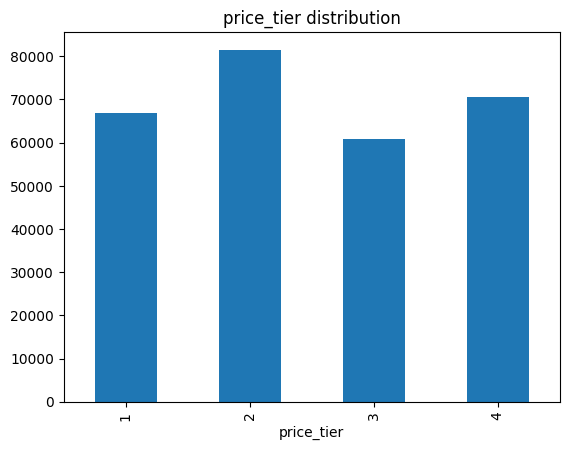

Majority-class macro F1: 0.1128361695767225


In [9]:
print(train[TARGET].value_counts().sort_index())
print(train[TARGET].value_counts(normalize=True).sort_index().round(3))
train[TARGET].value_counts().sort_index().plot(kind="bar", title="price_tier distribution"); plt.show()
maj = train[TARGET].mode()[0]
print("Majority-class macro F1:", f1_score(train[TARGET], [maj]*len(train), average="macro"))

                              train_%  test_%
borough                         76.66   75.12
score_value                     19.39   18.73
score_access                    19.39   18.73
score_onboarding                19.39   18.74
score_accuracy                  19.39   18.73
score_support                   19.39   18.73
last_review_date                19.39   18.73
reviews_per_month               19.39   18.73
score_condition                 19.39   18.73
first_review_date               19.39   18.73
score_overall                   19.39   18.73
zones                           17.31   18.42
utility_rooms                   10.69   10.59
workstations                     6.71    7.04
operator_active_years            0.22    0.19
operator_active_months           0.22    0.19
operator_has_avatar              0.22    0.19
operator_ref                     0.22    0.19
operator_id_verified             0.22    0.19
operator_platform_age_months     0.22    0.19
operator_platform_age_years      0

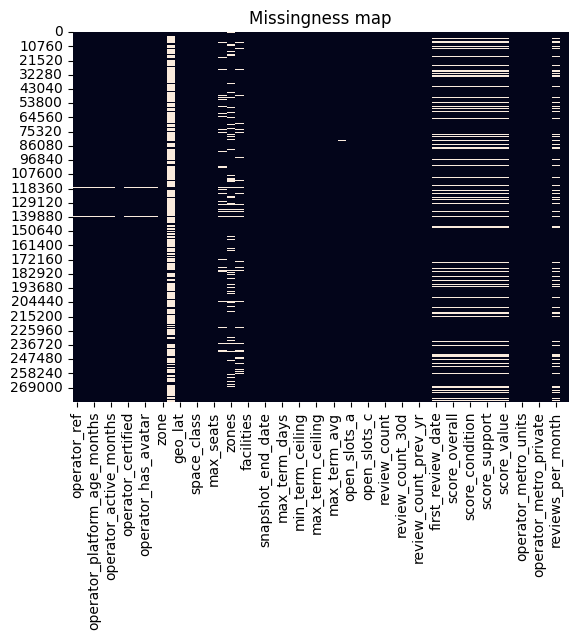

                              operator_ref  operator_platform_age_years  \
operator_ref                          1.00                         1.00   
operator_platform_age_years           1.00                         1.00   
operator_platform_age_months          1.00                         1.00   
operator_active_years                 1.00                         1.00   
operator_active_months                1.00                         1.00   
operator_certified                    1.00                         1.00   
operator_portfolio_size               1.00                         1.00   
operator_has_avatar                   1.00                         1.00   
operator_id_verified                  1.00                         1.00   
borough                              -0.05                        -0.05   
utility_rooms                         0.13                         0.13   
zones                                 0.10                         0.10   
workstations             

In [10]:
miss = pd.DataFrame({"train_%": train.isna().mean()*100, "test_%": test.isna().mean()*100})
print(miss[(miss > 0).any(axis=1)].sort_values("train_%", ascending=False).round(2))
sns.heatmap(train[feat].isna(), cbar=False); plt.title("Missingness map"); plt.show()

mc = train[feat].columns[train[feat].isna().any()]
print(train[mc].isna().corr().round(2))                       # do columns go missing together?
for c in mc[:8]:
    print(c, train.groupby(train[c].isna())[TARGET].value_counts(normalize=True).unstack().round(3))

In [11]:
X = train[feat]
print("exact duplicate rows:", X.duplicated().sum())
print("conflicting duplicates:", train[X.duplicated(keep=False)].groupby(feat, dropna=False)[TARGET].nunique().gt(1).sum())

def col(*names):  # helper: first matching column name
    return [c for c in train.columns if all(n in c for n in names)]
print("month cols:", col("months"))
for c in col("months"): print(c, "max =", train[c].max())
print("scores outside 0-10:", {c: ((train[c]<0)|(train[c]>10)).sum() for c in train.columns if c.startswith("score_")})

if {"operator_metro_units","operator_metro_whole","operator_metro_private","operator_metro_shared"} <= set(train.columns):
    s = train[["operator_metro_whole","operator_metro_private","operator_metro_shared"]].sum(axis=1)
    print("units != whole+private+shared:", (train["operator_metro_units"] != s).sum())
    print("metro units > portfolio:", (train["operator_metro_units"] > train["operator_portfolio_size"]).sum())
print("active > platform (years):", (train["operator_active_years"] > train["operator_platform_age_years"]).sum())
print(pd.crosstab(train["operator_class"], train["operator_certified"]))

print("negatives:", (train[num] < 0).sum()[lambda s: s>0].to_dict())
print("near-constant:", [c for c in feat if train[c].value_counts(normalize=True, dropna=False).iloc[0] > 0.99])

exact duplicate rows: 1160
conflicting duplicates: 43
month cols: ['operator_platform_age_months', 'operator_active_months']
operator_platform_age_months max = 11.0
operator_active_months max = 11.0
scores outside 0-10: {'score_overall': np.int64(0), 'score_accuracy': np.int64(0), 'score_condition': np.int64(0), 'score_onboarding': np.int64(0), 'score_support': np.int64(0), 'score_access': np.int64(0), 'score_value': np.int64(0)}
units != whole+private+shared: 3428
metro units > portfolio: 1849
active > platform (years): 3
operator_certified        f      t
operator_class                    
independent_operator  63402  48485
managed_operator      26970  13416
unverified_operator   89863  37006
negatives: {'geo_lat': 22706, 'geo_lon': 232422}
near-constant: ['bookable']


                                 count      mean          std     min     25%  \
operator_platform_age_years   279142.0      6.79         4.19    0.00    3.00   
operator_platform_age_months  279142.0      5.45         3.49    0.00    2.00   
operator_active_years         279140.0      5.08         4.04    0.00    2.00   
operator_active_months        279140.0      5.30         3.48    0.00    2.00   
operator_portfolio_size       279142.0     49.47       332.75    0.00    1.00   
geo_lat                       279746.0     77.77        37.51   -4.82   68.04   
geo_lon                       279746.0    -35.14        57.17 -123.75  -76.56   
max_seats                     279746.0      3.63         2.28    1.00    2.00   
utility_rooms                 249847.0      1.36         0.81    0.50    1.00   
zones                         231332.0      1.66         1.09    0.00    1.00   
workstations                  260963.0      2.16         1.71    1.00    1.00   
min_term_days               

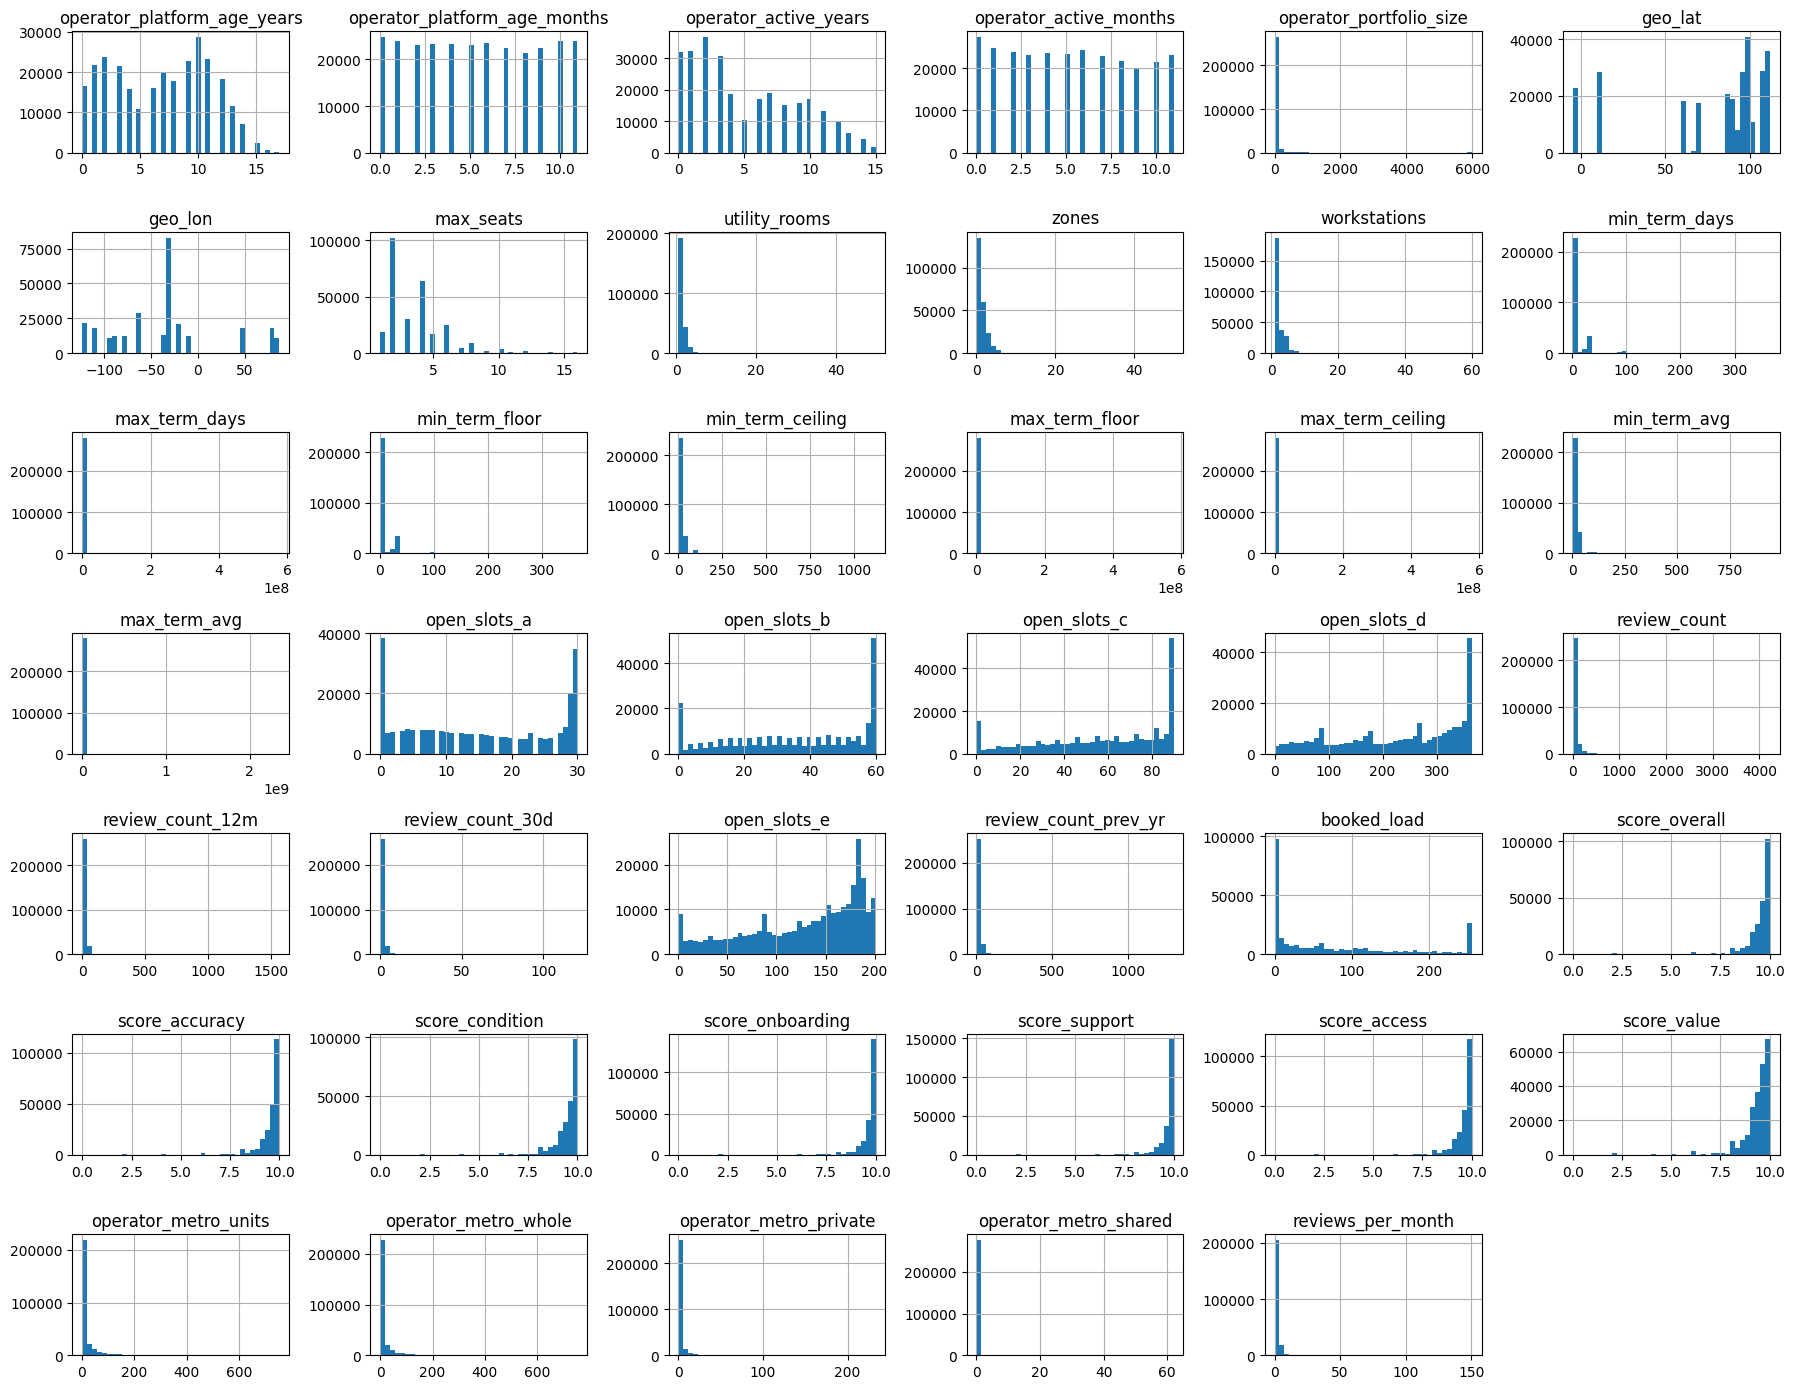

IQR outlier % per column:
 min_term_ceiling           20.63
min_term_avg               20.45
min_term_floor             18.98
min_term_days              18.98
geo_lat                    18.32
operator_metro_private     17.79
operator_metro_whole       16.07
operator_metro_units       14.35
operator_portfolio_size    14.22
review_count_30d           13.85
geo_lon                    10.38
review_count               10.17
review_count_prev_yr        9.92
review_count_12m            6.98
score_support               6.88
dtype: float64
skewed columns (|skew|>1): ['operator_portfolio_size', 'geo_lat', 'max_seats', 'utility_rooms', 'zones', 'workstations', 'min_term_days', 'max_term_days', 'min_term_floor', 'min_term_ceiling', 'max_term_floor', 'max_term_ceiling', 'min_term_avg', 'max_term_avg', 'review_count', 'review_count_12m', 'review_count_30d', 'review_count_prev_yr', 'score_overall', 'score_accuracy', 'score_condition', 'score_onboarding', 'score_support', 'score_access', 'score_value'

In [12]:
print(train[num].describe().T.assign(skew=train[num].skew()).round(2))
train[num].hist(bins=40, figsize=(18,14)); plt.tight_layout(); plt.show()
q1, q3 = train[num].quantile(.25), train[num].quantile(.75); iqr = q3 - q1
out = (((train[num] < q1-1.5*iqr) | (train[num] > q3+1.5*iqr)).mean()*100).round(2)
print("IQR outlier % per column:\n", out.sort_values(ascending=False).head(15))
print("skewed columns (|skew|>1):", train[num].skew()[lambda s: s.abs()>1].index.tolist())

In [13]:
for c in cat:
    print(f"\n{c}: {train[c].nunique()} unique")
    print(train[c].value_counts(normalize=True).head(8).round(3))
# operator overlap between train and test
print("test operators also in train:", test["operator_ref"].isin(train["operator_ref"]).mean().round(3))
print("listings per operator:\n", train["operator_ref"].value_counts().describe())


operator_ref: 41903 unique
operator_ref
Bessstu       0.005
Zianovath     0.004
Nalsto        0.004
Dessselra     0.004
Stianianlo    0.003
Klynfova      0.003
Sinnovara     0.003
Zelten        0.003
Name: proportion, dtype: float64

operator_class: 3 unique
operator_class
unverified_operator     0.456
independent_operator    0.400
managed_operator        0.144
Name: proportion, dtype: float64

operator_certified: 2 unique
operator_certified
f    0.646
t    0.354
Name: proportion, dtype: float64

operator_has_avatar: 2 unique
operator_has_avatar
t    0.958
f    0.042
Name: proportion, dtype: float64

operator_id_verified: 2 unique
operator_id_verified
t    0.986
f    0.014
Name: proportion, dtype: float64

zone: 1380 unique
zone
ZN-0923    0.039
ZN-0779    0.034
ZN-0948    0.031
ZN-0536    0.017
ZN-1039    0.013
ZN-0454    0.013
ZN-0812    0.011
ZN-0315    0.010
Name: proportion, dtype: float64

borough: 55 unique
borough
BRG-18    0.163
BRG-30    0.141
BRG-22    0.134
BRG-14    0.082

In [14]:
s = train.sample(20000, random_state=42)
print(s.shape)
print(s["price_tier"].value_counts(normalize=True).sort_index().round(3))

(20000, 60)
price_tier
1    0.235
2    0.293
3    0.216
4    0.256
Name: proportion, dtype: float64


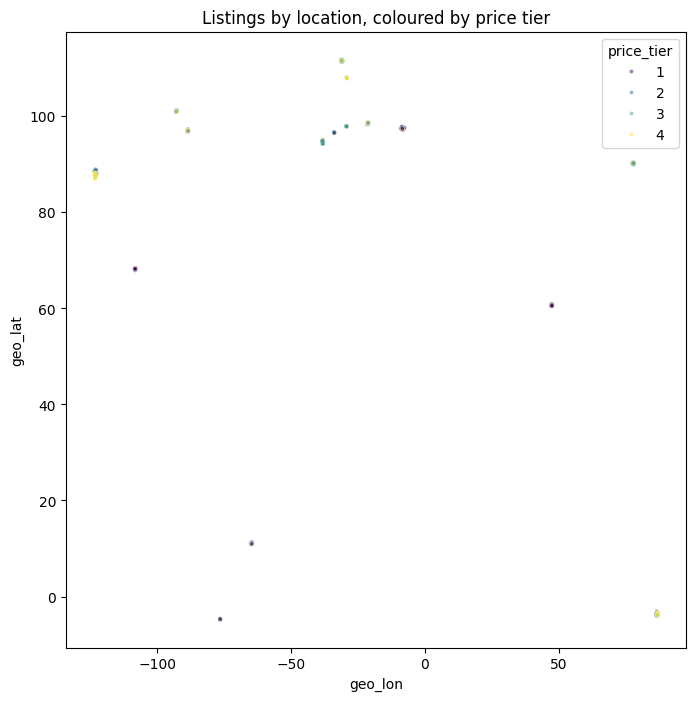

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 8))
sns.scatterplot(data=s, x="geo_lon", y="geo_lat", hue="price_tier",
                palette="viridis", s=8, alpha=0.5)
plt.title("Listings by location, coloured by price tier")
plt.show()

In [16]:
cat_cols = s.select_dtypes(exclude="number").columns
print(s[cat_cols].nunique().sort_values())
print(s["facilities"].head(3).tolist())

operator_has_avatar         2
operator_certified          2
operator_id_verified        2
bookable                    2
operator_class              3
access_type                 4
compliance_status           4
metro                      16
borough                    54
space_class                82
snapshot_start_date       323
snapshot_end_date         351
zone                     1039
last_review_date         1489
first_review_date        3608
operator_ref             8733
facilities              19435
dtype: int64
['["FCL-012", "FCL-104", "FCL-058", "FCL-085", "FCL-098", "FCL-138", "FCL-040", "FCL-139", "FCL-007", "FCL-141", "FCL-093", "FCL-005", "FCL-142", "FCL-136", "FCL-106", "FCL-056", "FCL-042", "FCL-143", "FCL-083", "FCL-118", "FCL-080", "FCL-014", "FCL-035", "FCL-090", "FCL-030", "FCL-099", "FCL-145", "FCL-087", "FCL-078", "FCL-020"]', '["FCL-071", "FCL-072", "FCL-093", "FCL-138", "FCL-137", "FCL-080", "FCL-055", "FCL-029", "FCL-056", "FCL-135", "FCL-132", "FCL-077", "FCL-139

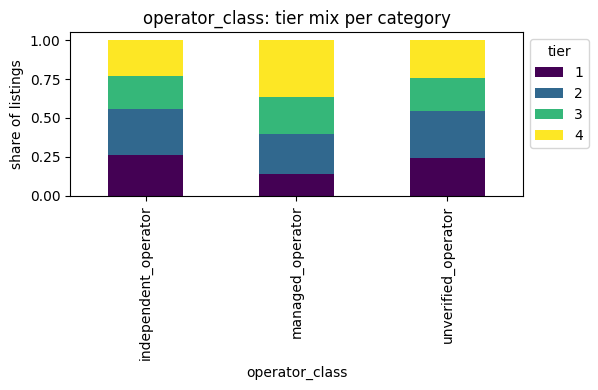

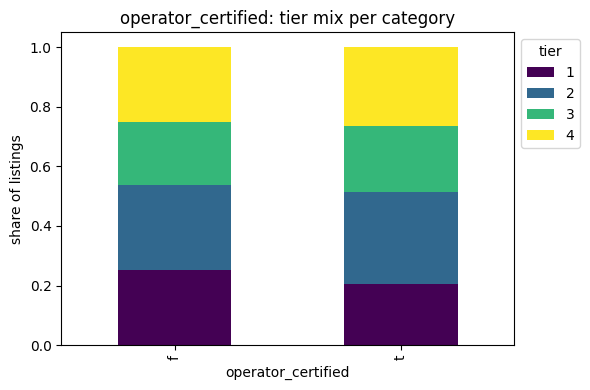

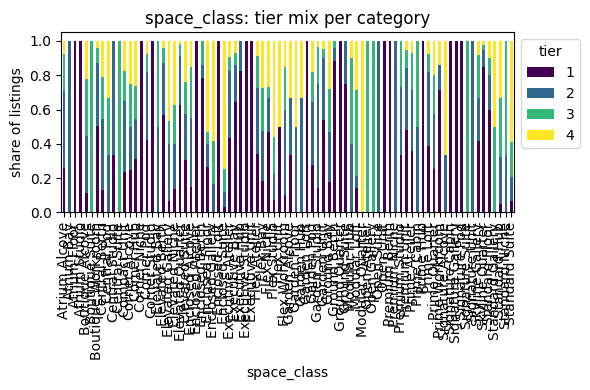

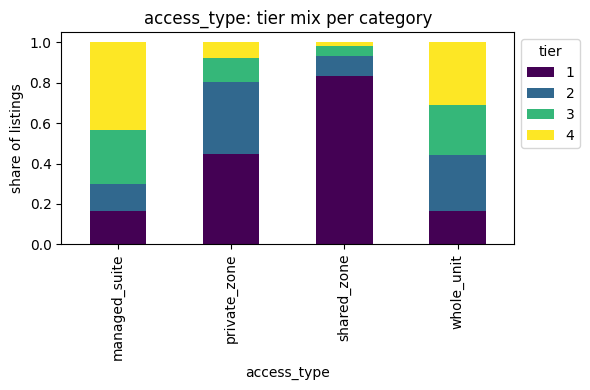

In [17]:
for c in ["operator_class", "operator_certified", "space_class", "access_type"]:
    pd.crosstab(s[c], s["price_tier"], normalize="index").plot(
        kind="bar", stacked=True, figsize=(6, 4), colormap="viridis")
    plt.title(c + ": tier mix per category")
    plt.ylabel("share of listings")
    plt.legend(title="tier", bbox_to_anchor=(1, 1))
    plt.tight_layout()
    plt.show()

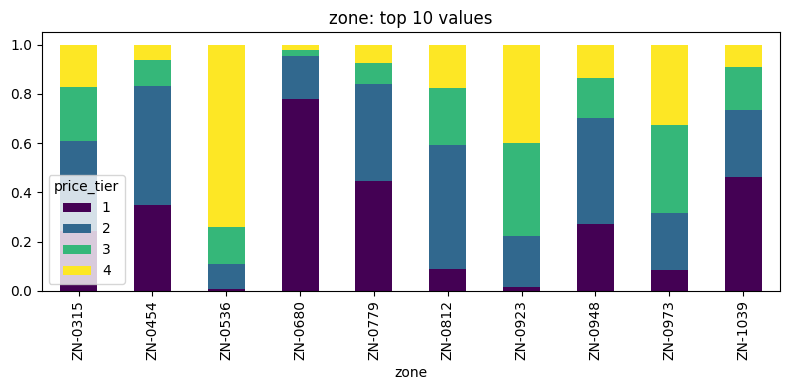

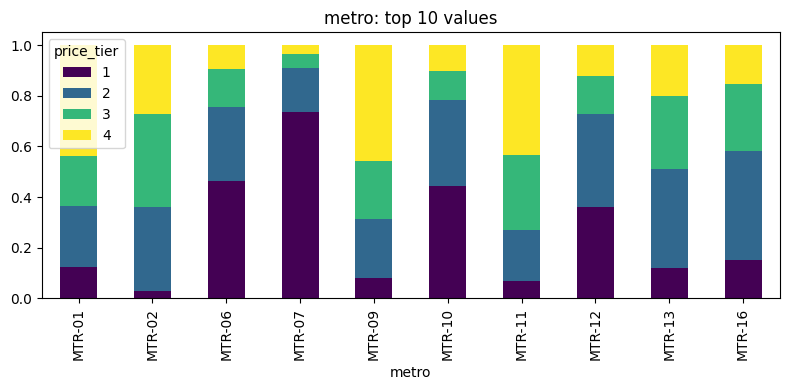

In [18]:
for c in ["zone", "metro"]:
    top = s[c].value_counts().head(10).index
    sub = s[s[c].isin(top)]
    pd.crosstab(sub[c], sub["price_tier"], normalize="index").plot(
        kind="bar", stacked=True, figsize=(8, 4), colormap="viridis")
    plt.title(c + ": top 10 values")
    plt.tight_layout()
    plt.show()

In [19]:
import lightgbm as lgb   # preinstalled on Kaggle; otherwise: pip install lightgbm
from sklearn.model_selection import train_test_split, GroupKFold
from sklearn.metrics import f1_score

drop_cols = ["space_id", "operator_ref", "price_tier",
             "snapshot_start_date", "snapshot_end_date",
             "first_review_date", "last_review_date"]
X = train.drop(columns=drop_cols)
y = train["price_tier"] - 1          # LightGBM expects classes 0..3, not 1..4

for c in X.select_dtypes(exclude="number"):
    X[c] = X[c].astype("category")   # tells LightGBM these are categories

In [20]:
def fit_and_score(tr_idx, va_idx):
    m = lgb.LGBMClassifier(n_estimators=500, learning_rate=0.1,
                           class_weight="balanced", random_state=42, n_jobs=-1)
    m.fit(X.iloc[tr_idx], y.iloc[tr_idx],
          eval_set=[(X.iloc[va_idx], y.iloc[va_idx])],
          callbacks=[lgb.early_stopping(50), lgb.log_evaluation(100)])
    pred = m.predict(X.iloc[va_idx])
    return f1_score(y.iloc[va_idx], pred, average="macro"), m

In [21]:
feat_cols = [c for c in train.columns if c not in ("space_id", "price_tier")]

dup_mask = train.duplicated(subset=feat_cols, keep=False)
d = train[dup_mask]
n_labels = d.groupby(feat_cols, dropna=False)["price_tier"].transform("nunique")
bad_idx = d.index[n_labels > 1]                 # duplicates with contradicting tiers

train_clean = train.drop(index=bad_idx).drop_duplicates(subset=feat_cols).reset_index(drop=True)
print(len(train), "->", len(train_clean))

279746 -> 278543


In [22]:
def add_features(d):
    d = d.copy()
    for c in ["snapshot_start_date", "snapshot_end_date", "first_review_date", "last_review_date"]:
        d[c] = pd.to_datetime(d[c], errors="coerce")
    d["snapshot_span_days"] = (d["snapshot_end_date"] - d["snapshot_start_date"]).dt.days
    d["days_since_first_review"] = (d["snapshot_end_date"] - d["first_review_date"]).dt.days
    d["days_since_last_review"] = (d["snapshot_end_date"] - d["last_review_date"]).dt.days
    d["snapshot_month"] = d["snapshot_start_date"].dt.month

    d["platform_tenure"] = d["operator_platform_age_years"] + d["operator_platform_age_months"] / 12
    d["active_tenure"] = d["operator_active_years"] + d["operator_active_months"] / 12
    d["has_reviews"] = d["score_overall"].notna().astype(int)
    sc = [c for c in d.columns if c.startswith("score_")]
    d["score_mean"] = d[sc].mean(axis=1)

    # flag impossible values instead of deleting rows
    d["metro_sum_mismatch"] = (d["operator_metro_units"] !=
        d["operator_metro_whole"] + d["operator_metro_private"] + d["operator_metro_shared"]).astype(int)
    d["metro_over_portfolio"] = (d["operator_metro_units"] > d["operator_portfolio_size"]).astype(int)

    return d.drop(columns=["space_id", "operator_ref", "bookable",
                           "snapshot_start_date", "snapshot_end_date",
                           "first_review_date", "last_review_date"], errors="ignore")

In [23]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OrdinalEncoder

Xc = add_features(train_clean.drop(columns="price_tier"))
yc = train_clean["price_tier"] - 1
groups = train_clean["operator_ref"].fillna("missing")

cat_cols = Xc.select_dtypes(exclude="number").columns.tolist()

pre = ColumnTransformer(
    [("cat", OrdinalEncoder(handle_unknown="use_encoded_value",
                            unknown_value=-1, encoded_missing_value=-1), cat_cols)],
    remainder="passthrough")        # numeric columns pass through untouched

pipe = Pipeline([
    ("pre", pre),
    ("clf", lgb.LGBMClassifier(class_weight="balanced", random_state=42, n_jobs=-1, verbose=-1)),
])

In [24]:
import json, joblib, pandas as pd
from pathlib import Path
from sklearn.base import clone
from sklearn.model_selection import RandomizedSearchCV, GroupKFold
from scipy.stats import randint, uniform, loguniform

OUT = Path("/kaggle/working")

sub = Xc.sample(60000, random_state=42).index
Xs, ys, gs = Xc.loc[sub], yc.loc[sub], groups.loc[sub]

param_dist = {
    "clf__n_estimators":      randint(200, 800),
    "clf__learning_rate":     loguniform(0.02, 0.2),
    "clf__num_leaves":        randint(31, 200),
    "clf__min_child_samples": randint(20, 200),
    "clf__subsample":         uniform(0.6, 0.4),
    "clf__subsample_freq":    [1],
    "clf__colsample_bytree":  uniform(0.5, 0.5),
    "clf__reg_lambda":        loguniform(0.01, 10),
}

search = RandomizedSearchCV(pipe, param_dist, n_iter=15, cv=GroupKFold(3),
                            scoring="f1_macro", random_state=42, n_jobs=1, verbose=2)
search.fit(Xs, ys, groups=gs)

print("Best macro F1:", round(search.best_score_, 4))
print(search.best_params_)

# save everything worth keeping
joblib.dump(search.best_estimator_, OUT / "best_model.joblib")      # full pipeline, fitted on the 60k sample
pd.DataFrame(search.cv_results_).to_csv(OUT / "search_results.csv", index=False)
json.dump({"f1_macro": float(search.best_score_),
           "params": {k: (v.item() if hasattr(v, "item") else v) for k, v in search.best_params_.items()}},
          open(OUT / "best_params.json", "w"), indent=2)

# refit the winning settings on all the data and save that too
final = clone(pipe).set_params(**search.best_params_).fit(Xc, yc)
joblib.dump(final, OUT / "final_pipe.joblib")

Fitting 3 folds for each of 15 candidates, totalling 45 fits
[CV] END clf__colsample_bytree=0.6872700594236812, clf__learning_rate=0.1785436060870726, clf__min_child_samples=126, clf__n_estimators=271, clf__num_leaves=51, clf__reg_lambda=0.02938027938703535, clf__subsample=0.662397808134481, clf__subsample_freq=1; total time=   9.7s
[CV] END clf__colsample_bytree=0.6872700594236812, clf__learning_rate=0.1785436060870726, clf__min_child_samples=126, clf__n_estimators=271, clf__num_leaves=51, clf__reg_lambda=0.02938027938703535, clf__subsample=0.662397808134481, clf__subsample_freq=1; total time=   9.6s
[CV] END clf__colsample_bytree=0.6872700594236812, clf__learning_rate=0.1785436060870726, clf__min_child_samples=126, clf__n_estimators=271, clf__num_leaves=51, clf__reg_lambda=0.02938027938703535, clf__subsample=0.662397808134481, clf__subsample_freq=1; total time=   9.6s
[CV] END clf__colsample_bytree=0.5290418060840998, clf__learning_rate=0.146962368105409, clf__min_child_samples=119, 

['/kaggle/working/final_pipe.joblib']

In [25]:
sample = pd.read_csv("/kaggle/input/competitions/workstation-rental-price-tier-prediction/kaggle_ready_dataset/sample_submission.csv")
id_col, tgt_col = sample.columns[:2]

Xte = add_features(test)[Xc.columns]        # same feature function used to build Xc, same column order
pred = final.predict(Xte) + 1                # shift 0..3 back to tiers 1..4

submission = pd.DataFrame({id_col: test["space_id"].values, tgt_col: pred})
assert len(submission) == len(sample) and set(submission[id_col]) == set(sample[id_col])

submission.to_csv("/kaggle/working/submission.csv", index=False)
print(submission.shape)
print(submission[tgt_col].value_counts(normalize=True).sort_index().round(3))

(114538, 2)
price_tier
1    0.252
2    0.302
3    0.217
4    0.228
Name: proportion, dtype: float64


In [26]:
best = {
    "clf__colsample_bytree": 0.7247253370691017,
    "clf__learning_rate": 0.024913807939754118,
    "clf__min_child_samples": 170,
    "clf__n_estimators": 773,
    "clf__num_leaves": 67,
    "clf__reg_lambda": 1.5446089075047076,
    "clf__subsample": 0.8550229885420852,
    "clf__subsample_freq": 1,
}
final = clone(pipe).set_params(**best).fit(Xc, yc)